# Figures: the gap source on the thin-strip case of Ding et al. (2013)

Generates, for the page *Theory → Excitations and input impedance*:

- `excitation_gap_window.svg`: which RWG functions the gap source of the solver feeds, and with which $V_m$;
- `excitation_strip_impedance.svg`: input impedance of the centre-fed strip of Ding et al. (2013), Table I, computed by the solver, against the values published for their model.

Test case (Ding et al., Sec. III-A): half-wave strip, 75 MHz, 2 m × 5 cm, centre-fed, gap of width $W$ meshed with 5 RWG edges. The mesh is a structured grid (`solver.optim.geometries.planar.tensor_grid_mesh`, no gmsh) with one cell across the width and grid lines at $x = -W/2, 0, +W/2$, which gives exactly the 5 gap edges of their Fig. 1. The rest of the strip is cut into identical segments so that the triangle counts match their Table I. Their mesh is not published in detail, so the comparison is between two meshes of the same kind, not the same mesh.

Everything runs in memory with the solver's functions (`gap_source.multiple_gap_sources`, `rwg3.calculate_z_matrice`, `rwg4.compute_port_results`): nothing is written to `data/`.

In [1]:
%matplotlib inline
import datetime
import json
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from fontTools.ttLib import TTFont
from matplotlib import font_manager
from matplotlib.patches import Polygon, Rectangle

from solver.optim.geometries.planar import tensor_grid_mesh
from solver.rwg.rwg3 import calculate_z_matrice
from solver.rwg.rwg4 import compute_port_results
from solver.utils.gap_source import multiple_gap_sources, GapSourceError

OUT_DIR = Path("../source/figures/generated")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, AMBER, INK, GREY = "#2563a6", "#e28a36", "#142b45", "#9aa5b1"
W_COLOURS = [BLUE, AMBER, INK, "#3a9a7a", "#8a5cc2"]
font_cache = Path(tempfile.gettempdir()) / "antenna_solver_docs_fonts"
font_cache.mkdir(exist_ok=True)
for variant in ("400-normal", "400-italic", "700-normal"):
    ttf = font_cache / f"iosevka-{variant}.ttf"
    if not ttf.exists():
        font = TTFont(Path("../source/_static/fonts/iosevka") / f"iosevka-latin-{variant}.woff2")
        font.flavor = None
        font.save(ttf)
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams.update({
    "font.family": "Iosevka", "font.size": 11, "svg.fonttype": "path",
    "mathtext.fontset": "custom", "mathtext.rm": "Iosevka",
    "mathtext.it": "Iosevka:italic", "mathtext.bf": "Iosevka:bold",
})

# Ding et al. (2013), Table I, column "New Model" (ohms): {gap width (m): {patches: Z}}
DING_TABLE_I = {
    0.1:     {24: 88 + 40j, 44: 89 + 44j, 84: 89 + 46j, 164: 90 + 48j},
    0.05:    {24: 89 + 40j, 44: 90 + 42j, 84: 91 + 44j, 164: 92 + 47j},
    0.025:   {24: 90 + 39j, 44: 91 + 40j, 84: 92 + 44j, 164: 92 + 47j},
    0.0125:  {24: 92 + 37j, 44: 93 + 38j, 84: 94 + 42j, 164: 95 + 44j},
    0.00625: {24: 96 + 23j, 44: 99 + 30j, 84: 101 + 34j, 164: 101 + 37j, 324: 101 + 37j},
}
LENGTH, WIDTH, FREQ, V0 = 2.0, 0.05, 75e6, 1.0

In [2]:
def strip_with_gap(W, patches):
    """Strip along x, one cell across, grid lines at -W/2, 0, +W/2; `patches` triangles in total."""
    n_cells = patches // 2                 # one cell across the width -> 2 triangles per cell
    n_out = (n_cells - 2) // 2             # cells on each side of the 2-cell gap
    left = np.linspace(-LENGTH / 2, -W / 2, n_out + 1)
    xs = np.concatenate([left, [0.0], -left[::-1]])
    ys = np.array([-WIDTH / 2, WIDTH / 2])
    return tensor_grid_mesh(xs, ys)

def solve(W, patches):
    """Z_in by the solver's definition (complex power) and by Ding's eq. (9) (centre-edge current)."""
    mesh = strip_with_gap(W, patches)
    tri, edg, rho = mesh.triangles, mesh.edges, mesh.vecteurs_rho
    V, feeding = multiple_gap_sources(tri, edg, rho, V0, [[0.0, 0.0, 0.0]], "x", W)
    *_, Z = calculate_z_matrice(mesh.points, tri, edg, FREQ)
    I = np.linalg.solve(Z, V)
    z_power = compute_port_results(V, I, feeding, V0, [[0.0, 0.0, 0.0]], verbose=False)[0]["impedance"]

    # Edges lying on a vertical grid line (same x for both end points) carry the x-current across
    P = mesh.points.points
    xa, xb = P[0, edg.first_points], P[0, edg.second_points]
    vertical = np.isclose(xa, xb)
    def current_across(x0):
        m = np.flatnonzero(vertical & np.isclose(xa, x0))
        return np.sum(I[m] * edg.edges_length[m])          # I_m l_m (T+ is the -x triangle)
    i_centre, i_left, i_right = current_across(0.0), current_across(-W / 2), current_across(W / 2)
    return dict(mesh=mesh, V=V, feeding=feeding[0], z_power=z_power, z_edge=V0 / i_centre,
                i_gap=(i_left, i_centre, i_right), n=edg.total_number_of_edges)

results, failures = {}, {}
for W, table in DING_TABLE_I.items():
    for patches in table:
        try:
            results[(W, patches)] = solve(W, patches)
        except GapSourceError as exc:
            failures[(W, patches)] = str(exc).split(":")[0]

print(f"{'W (m)':>8s} {'patches':>7s} {'N':>4s} {'solver Z_in (power)':>22s} {'Z = V/(I l), eq. 9':>22s} {'Ding, new model':>16s}  spread of I l across the gap")
for (W, patches), r in results.items():
    i_l, i_c, i_r = r["i_gap"]
    spread = max(abs(i_l - i_c), abs(i_r - i_c)) / abs(i_c)
    print(f"{W:8.5f} {patches:7d} {r['n']:4d} {r['z_power']:22.2f} {r['z_edge']:22.2f} {DING_TABLE_I[W][patches]:16} {100 * spread:8.2f} %")
print("\nNot computed (GapSourceError):")
for (W, patches), msg in failures.items():
    print(f"  W = {W} m, {patches} patches")

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (163x163 edges).


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (163x163 edges).


[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (163x163 edges).


   W (m) patches    N    solver Z_in (power)     Z = V/(I l), eq. 9  Ding, new model  spread of I l across the gap
 0.10000      24   23           87.33+46.08j           87.97+45.53j         (88+40j)     1.97 %
 0.10000      44   43           88.50+47.21j           89.11+46.67j         (89+44j)     1.85 %
 0.10000      84   83           89.06+47.88j           89.64+47.34j         (89+46j)     1.77 %
 0.10000     164  163           89.33+48.27j           89.91+47.74j         (90+48j)     1.71 %
 0.05000      24   23           88.10+45.41j           88.76+44.95j         (89+40j)     1.82 %
 0.05000      44   43           89.47+46.36j           90.07+45.91j         (90+42j)     1.67 %
 0.05000      84   83           90.11+46.95j           90.68+46.52j         (91+44j)     1.55 %
 0.05000     164  163           90.43+47.34j           90.97+46.92j         (92+47j)     1.46 %
 0.02500      24   23           88.68+44.93j           89.34+44.47j         (90+39j)     1.77 %
 0.02500      44   43

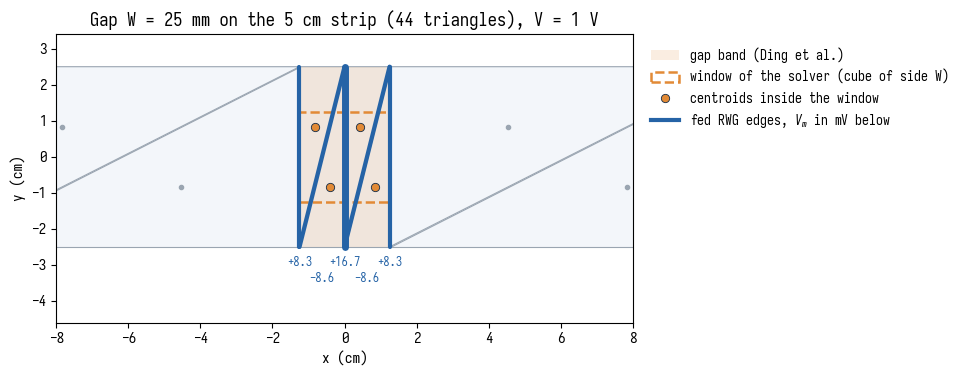

In [3]:
# (a) What the gap source feeds: W = 2.5 cm, 44 patches, zoom on the gap.
# The solver's window is a cube of side W centred on the feed point; on this strip it is
# narrower than the gap band, which is why gaps below 16.7 mm feed nothing (centroids at |y| = 8.3 mm).
W_SHOW, P_SHOW = 0.025, 44
r = results[(W_SHOW, P_SHOW)]
mesh, V = r["mesh"], r["V"]
P = mesh.points.points
tri = mesh.triangles
cm = 1e2

fig, ax = plt.subplots(figsize=(11, 3.9))
for t in range(tri.total_of_triangles):
    ax.add_patch(Polygon(P[:2, tri.triangles[:3, t]].T * cm, closed=True, fc="#f3f6fa", ec=GREY, lw=0.8))
ax.add_patch(Rectangle((-W_SHOW / 2 * cm, -WIDTH / 2 * cm), W_SHOW * cm, WIDTH * cm, fc=AMBER, alpha=0.15, ec="none",
                       label="gap band (Ding et al.)"))
ax.add_patch(Rectangle((-W_SHOW / 2 * cm, -W_SHOW / 2 * cm), W_SHOW * cm, W_SHOW * cm, fill=False, ec=AMBER, lw=1.8, ls="--",
                       label="window of the solver (cube of side W)"))
c = tri.triangles_center
inside = np.all(np.abs(c) <= W_SHOW / 2 + 1e-15, axis=0)
ax.plot(c[0, ~inside] * cm, c[1, ~inside] * cm, "o", color=GREY, ms=3)
ax.plot(c[0, inside] * cm, c[1, inside] * cm, "o", color=AMBER, ms=6, mec=INK, mew=0.6, label="centroids inside the window")
# fed RWG edges (blue), line width proportional to |V_m|; values written under the strip
e = mesh.edges
vmax = np.abs(V).max()
fed = sorted(r["feeding"], key=lambda m: P[0, e.first_points[m]] + P[0, e.second_points[m]])
for i, m in enumerate(fed):
    a, b = e.first_points[m], e.second_points[m]
    ax.plot(P[0, [a, b]] * cm, P[1, [a, b]] * cm, color=BLUE, lw=1 + 4 * abs(V[m]) / vmax, solid_capstyle="round")
    x_mid = 0.5 * (P[0, a] + P[0, b]) * cm
    ax.annotate(f"{1e3 * V[m].real:+.1f}", (x_mid, -WIDTH / 2 * cm), xytext=(0, -14 - 11 * (i % 2)),
                textcoords="offset points", ha="center", fontsize=9, color=BLUE)
ax.plot([], [], color=BLUE, lw=3, label=r"fed RWG edges, $V_m$ in mV below")
ax.set_xlim(-8, 8)
ax.set_ylim(-4.6, 3.4)
ax.set_aspect("equal")
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=10)
ax.set_title(f"Gap W = {W_SHOW * 1000:g} mm on the 5 cm strip ({P_SHOW} triangles), V = 1 V")
fig.tight_layout()
fig.savefig(OUT_DIR / "excitation_gap_window.svg", bbox_inches="tight", facecolor="white")
plt.show()

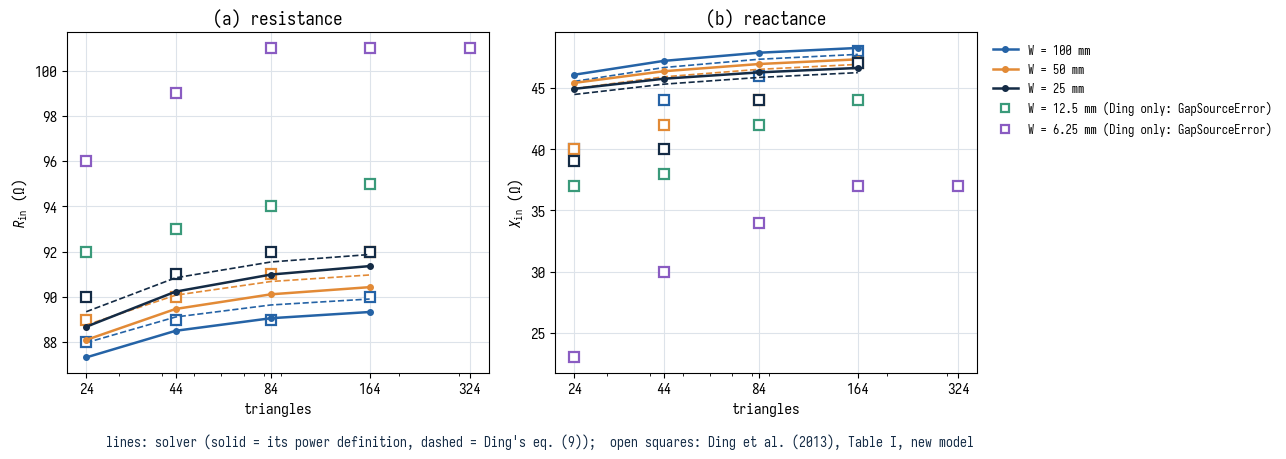

In [4]:
# (b) Input impedance against Ding et al., Table I
fig, (ax_r, ax_x) = plt.subplots(1, 2, figsize=(13, 4.4), sharex=True)
for colour, W in zip(W_COLOURS, DING_TABLE_I):
    ref_p = sorted(DING_TABLE_I[W])
    ref = np.array([DING_TABLE_I[W][p] for p in ref_p])
    got = sorted(p for (w, p) in results if w == W)
    label = f"W = {W * 1000:g} mm" + ("" if got else " (Ding only: GapSourceError)")
    ax_r.plot(ref_p, ref.real, "s", mfc="white", mec=colour, ms=7, mew=1.6)
    ax_x.plot(ref_p, ref.imag, "s", mfc="white", mec=colour, ms=7, mew=1.6)
    if got:
        zp = np.array([results[(W, p)]["z_power"] for p in got])
        ze = np.array([results[(W, p)]["z_edge"] for p in got])
        ax_r.plot(got, zp.real, "-o", color=colour, ms=4, lw=1.8)
        ax_x.plot(got, zp.imag, "-o", color=colour, ms=4, lw=1.8, label=label)
        ax_r.plot(got, ze.real, "--", color=colour, lw=1.2)
        ax_x.plot(got, ze.imag, "--", color=colour, lw=1.2)
    else:
        ax_x.plot([], [], "s", mfc="white", mec=colour, mew=1.6, label=label)
for ax, name in ((ax_r, r"$R_\mathrm{in}$ ($\Omega$)"), (ax_x, r"$X_\mathrm{in}$ ($\Omega$)")):
    ax.set_xscale("log")
    ax.set_xticks([24, 44, 84, 164, 324])
    ax.set_xticklabels(["24", "44", "84", "164", "324"])
    ax.set_xlabel("triangles")
    ax.set_ylabel(name)
    ax.grid(True, color="#dde3ea", lw=0.8)
ax_r.set_title("(a) resistance")
ax_x.set_title("(b) reactance")
ax_x.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.text(0.42, -0.03, "lines: solver (solid = its power definition, dashed = Ding's eq. (9));  open squares: Ding et al. (2013), Table I, new model",
         ha="center", fontsize=10, color=INK)
fig.tight_layout()
fig.savefig(OUT_DIR / "excitation_strip_impedance.svg", bbox_inches="tight", facecolor="white")
plt.show()

In [5]:
def git_commit(repo=Path("../..")):
    """Current commit, read from .git directly (git may not be on the kernel's PATH)."""
    git_dir = repo / ".git"
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]
    ref_file = git_dir / head[5:]
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (git_dir / "packed-refs").read_text().splitlines():
        if line.endswith(" " + head[5:]):
            return line.split()[0][:7]
    return "unknown"

def cplx(z):
    return [round(float(np.real(z)), 2), round(float(np.imag(z)), 2)]

provenance = {
    "figures": ["excitation_gap_window.svg", "excitation_strip_impedance.svg"],
    "notebook": "documentation/figure_notebooks/theory_excitations.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "case": {"length_m": LENGTH, "width_m": WIDTH, "frequency_hz": FREQ, "voltage_v": V0,
             "reference": "Ding et al. 2013, Table I (new model)"},
    "results": [{"W_m": W, "triangles": p, "N": r["n"], "Z_power": cplx(r["z_power"]),
                 "Z_edge_eq9": cplx(r["z_edge"]), "Z_ding": cplx(DING_TABLE_I[W][p]),
                 "I_l_left_centre_right": [cplx(i) for i in r["i_gap"]]}
                for (W, p), r in results.items()],
    "gap_source_error": [{"W_m": W, "triangles": p} for (W, p) in failures],
}
(OUT_DIR / "excitations.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(json.dumps({k: provenance[k] for k in ("solver_commit", "gap_source_error")}, indent=2))

{
  "solver_commit": "935470d",
  "gap_source_error": [
    {
      "W_m": 0.0125,
      "triangles": 24
    },
    {
      "W_m": 0.0125,
      "triangles": 44
    },
    {
      "W_m": 0.0125,
      "triangles": 84
    },
    {
      "W_m": 0.0125,
      "triangles": 164
    },
    {
      "W_m": 0.00625,
      "triangles": 24
    },
    {
      "W_m": 0.00625,
      "triangles": 44
    },
    {
      "W_m": 0.00625,
      "triangles": 84
    },
    {
      "W_m": 0.00625,
      "triangles": 164
    },
    {
      "W_m": 0.00625,
      "triangles": 324
    }
  ]
}
